.. index:: Equations; Laplace

# Introduction

## A Laplace problem

As an introduction we will solve
\begin{equation}
-\triangle u + u = f
\end{equation}
in $\Omega=[0,1]^2$, where $f=f(x)$ is a given forcing term.
On the boundary we prescribe Neumann boundary
$\nabla u\cdot n = 0$.

We will solve this problem in variational form
$a(u,v) = l(v)$ with
\begin{equation}
a(u,v) := \int_\Omega \nabla u\cdot\nabla v + uv~,\qquad
l(v) := \int_\Omega fv~.
\end{equation}
We choose $f=(8\pi^2+1)\cos(2\pi x_1)\cos(2\pi x_2)$
so that the exact solution is
\begin{align*}
u(x) = \cos(2\pi x_1)\cos(2\pi x_2)
\end{align*}

We first need to setup a tessellation of $\Omega$. We use a Cartesian
grid with a 20 cells in each coordinate direction

In [1]:
import matplotlib
matplotlib.rc( 'image', cmap='jet' )
import numpy as np

from dune.grid import structuredGrid
gridView = structuredGrid([0, 0], [1, 1], [20, 20])

Next we define a linear Lagrange Finite-Element space over that grid
and setup a discrete function which we will store the discrete solution
to our PDE

In [2]:
from dune.fem.space import lagrange
space = lagrange(gridView, order=1)
u_h   = space.interpolate(0, name='u_h')

We define the mathematical problem using ufl

In [3]:
from ufl import (TestFunction, TrialFunction, SpatialCoordinate,
                 dx, grad, inner, dot, sin, cos, pi )
x = SpatialCoordinate(space)
u = TrialFunction(space)
v = TestFunction(space)

f = (8*pi**2+1) * cos(2*pi*x[0])*cos(2*pi*x[1])
a = ( inner(grad(u),grad(v)) + u*v ) * dx
l = f*v * dx

Now we can assemble the matrix and the right hand side

In [4]:
from dune.fem import assemble
mat,rhs = assemble(a==l)

We solve the resulting linear system of equations $Ay=b$ using scipy.
To this end it is straightforward to expose the underlying data
structures in $A,b,u_h$ using the ``as_numpy`` attribute

In [5]:
from scipy.sparse.linalg import spsolve as solver

A = mat.as_numpy
b = rhs.as_numpy
y = u_h.as_numpy
y[:] = solver(A,b)

Note the ``y[:]`` which guarantees that the result from the solver is
stored in the same buffer used for the discrete function. Consequently,
no copying is required.

So that's it - to see the result we plot it using matplotlib

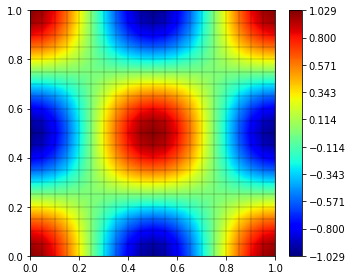

In [6]:
u_h.plot()

Since in this case the exact solution is known,
we can also compute the $L^2$ and $H^1$ errors to see how good our
approximation actually is

In [7]:
from dune.fem.function import integrate
exact = cos(2*pi*x[0])*cos(2*pi*x[1])
e_h = u_h-exact
squaredErrors = integrate(gridView, [e_h**2,inner(grad(e_h),grad(e_h))], order=5)
print("L^2 and H^1 errors:",[np.sqrt(e) for e in squaredErrors])

L^2 and H^1 errors: [0.004816996589370565, 0.4026000450756812]


## A Non-linear elliptic problem
.. index:: Equations; Non-linear elliptic

It is very easy to solve a non-linear elliptic problem with very few
changes to the above code.
We will demonstrate this using the PDE
\begin{equation}
-\triangle u + m(u) = f
\end{equation}
in $\Omega=[0,1]^2$, where again $f=f(x)$ is a given forcing term
and $m=m(u)$ is some non-linearity.
On the boundary we still prescribe Neumann boundary
$\nabla u\cdot n = 0$.

We will solve this problem in variational form
\begin{equation}
\int_\Omega \nabla u\cdot\nabla v + m(u)v = \int_\Omega fv~.
\end{equation}
We keep the same forcing $f(x)=|x|^2$ as before and choose
$m(u) = (1+u)^2u$.
Most of the code is identical to the linear case, we can use the same
grid, discrete lagrange space, and the discrete function ``u_h``.
The model description using ufl is also very similar

In [8]:
a = ( inner(grad(u),grad(v)) + (1+u)**2*u*v ) * dx
l = dot(x,x)*v * dx

To solve the non-linear problem we need to use something like a Newton
solver. We could use the implementation available in Scipy but
``dune-fem`` provides ``schemes`` that have a ``solve`` method
that can handle both linear and non-linear models. The default method is
a Newton-Krylov solver using a ``gmres`` method to solve the intermediate
linear problems. Since the problem here is symmetric we can use a ``cg``
method.

In [9]:
from dune.fem.scheme import galerkin as solutionScheme
scheme = solutionScheme(a == l, solver='cg')
u_h.clear() # set u_h to zero as initial guess for the Newton solver
info = scheme.solve(target=u_h)

That's it - we can plot the solution again - we don't know the exact
solution so we can't compute any errors in this case.
In addition the ``info`` structured returned by the ``solve`` method
gives some information on the solver step

{'converged': True, 'iterations': 5, 'linear_iterations': 250}


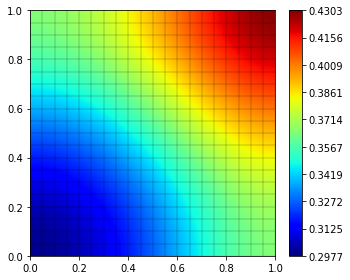

In [10]:
print(info)
u_h.plot()

.. index:: Equations; Non-linear parabolic

## A Nonlinear Time Dependent Problem

As a second example we will study the Forchheimer problem
<cite data-cite="Kieu"></cite>
which is a scalar, nonlinear parabolic equation
\begin{equation}
\partial_tu - \nabla\cdot K(\nabla u)\nabla u = f
\end{equation}
where the diffusion tensor is given by
\begin{equation}
K(\nabla u) = \frac{2}{1+\sqrt{1+4|\nabla u|}}
\end{equation}
and $f=f(x,t)$ is some time dependent forcing term.
On the boundary we prescribe Neumann boundary as before
and initial conditions $u=u_0$.

We will solve this problem in variational form and using Crank Nicholson in time
\begin{equation}
\begin{split}
\int_{\Omega} \frac{u^{n+1}-u^n}{\Delta t} \varphi
+ \frac{1}{2}K(\nabla u^{n+1}) \nabla u^{n+1} \cdot \nabla \varphi \
+ \frac{1}{2}K(\nabla u^n) \nabla u^n \cdot \nabla \varphi v\ dx \\
- \int_{\Omega} \frac{1}{2}(f(x,t^n)+f(x,t^n+\Delta t) \varphi\ dx
- \int_{\partial \Omega} \frac{1}{2}(g(x,t^n)+g(x,t^n+\Delta t)) v\ ds
= 0.
\end{split}
\end{equation}
on a domain $\Omega=[0,1]^2$. We choose $f,g$ so that the exact solution
is given by
\begin{align*}
u(x,t) = e^{-2t}\left(\frac{1}{2}(x^2 + y^2) - \frac{1}{3}(x^3 - y^3)\right) + 1
\end{align*}
We solve this problem using a quadratic finite element space.
We first setup this space, define the initial data,
and a second discrete function to store
the solution at the current time step (``u_h`` will be used to store the
next time step):

In [11]:
space = lagrange(gridView, order=2)
u_h   = space.interpolate(0, name='u_h')
u_h_n = u_h.copy(name="previous")

x = SpatialCoordinate(space)
initial = 1/2*(x[0]**2+x[1]**2) - 1/3*(x[0]**3 - x[1]**3) + 1

Next we setup the form $a=a(u,v)$ which depends on time $t$ and the
chosen time step $\Delta t$. Since we want to be able to change these
during the simulation (we need to do this for $t$ and might want to do
this for $\Delta t$ we use the ``dune.ufl.Constant`` which stores a
mutable scalar and can be used within a ufl expression:

In [12]:
from ufl import FacetNormal, ds, div, dot, sqrt, exp
from dune.ufl import Constant
dt = Constant(0, name="dt")    # time step
t  = Constant(0, name="t")     # current time
u = TrialFunction(space)
v = TestFunction(space)

abs_du = lambda u: sqrt(inner(grad(u), grad(u)))
K = lambda u: 2/(1 + sqrt(1 + 4*abs_du(u)))
a = ( dot((u - u_h_n)/dt, v) \
    + 0.5*dot(K(u)*grad(u), grad(v)) \
    + 0.5*dot(K(u_h_n)*grad(u_h_n), grad(v)) ) * dx

To define the right hand side we use the given function $u$ to define
the forcing $f$ and the boundary flux $g$

In [13]:
exact = lambda t: exp(-2*t)*(initial - 1) + 1
f     = lambda s: -2*exp(-2*s)*(initial - 1) - div( K(exact(s))*grad(exact(s)) )
g = lambda s: K(exact(s))*grad(exact(s))
n = FacetNormal(space)
b = 0.5*(f(t)+f(t+dt))*v*dx + 0.5*dot(g(t)+g(t+dt),n)*v*ds

With the model described as a ufl form, we can again construct a scheme class
that provides the solve method which we can use to evolve the solution from
one time step to the next. As already mentioned the solve methods always assumes
that the problem is non-linear and use a Newton method to solve the problem:

In [14]:
scheme = solutionScheme(a == b, solver='cg')

Optionally, we may want to increase the default quadrature orders which are
'2 * space.order' for element integrals and '2 * space.order + 1' for surface
integrals. Depending on the data this might not be enough. Then we simply
set the integration orders by hand like in the following example, by calling
the method setQuadratureOrders(interiorOrder, surfaceOrder).

In [15]:
#scheme.setQuadratureOrders( 2*space.order, 2*space.order+1 )

Since we have forced the system towards a given solution, we can compute
the discretization error. First we define ufl expressions for the $L^2$
and $H^1$ norms and will use those to compute the experimental order of
convergence of the scheme by computing the time evolution on different grid
levels. We use ``dune.fem.function.uflFunction`` to generate code for the
errors which can be more efficient than using the ufl expressions
directly.

In [16]:
from dune.fem.function import uflFunction
endTime    = 0.25
exact_end  = exact(endTime)
l2error = uflFunction(gridView, name="l2error", order=u_h.space.order, ufl=dot(u_h - exact_end, u_h - exact_end))
h1error = uflFunction(gridView, name="h1error", order=u_h.space.order, ufl=dot(grad(u_h - exact_end), grad(u_h - exact_end)))

.. index::
   pair: I/O; Writing VTK files

Now we evolve the solution from time $t=0$ to $t=T$ in a loop. Since the
PDE model has time dependent coefficient (through the forcing term), we
need to update the `t` constant used to define the model before each step.
A second constant we used to define the model was `dt` which defines the
time step. We keep this constant and set it to $0.002$ at the beginning
of the simulation. This value could be changed in each time step:

grid size: 400
	 | u_h - u | = 1.63852e-01
	 | grad(uh - u) | = 4.06373e-01


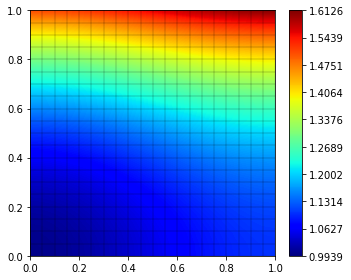

In [17]:
scheme.model.dt = 0.002
u_h.interpolate(initial)
time = 0
u_h = space.interpolate(initial, name='u_h')
while time < (endTime - 1e-6):
    scheme.model.t = time
    u_h_n.assign(u_h)
    scheme.solve(target=u_h)
    time += scheme.model.dt

errors = [np.sqrt(e) for e in integrate(gridView, [l2error,h1error], order=5)]
print('grid size:', gridView.size(0))
print('\t | u_h - u | =', '{:0.5e}'.format(errors[0]))
print('\t | grad(uh - u) | =', '{:0.5e}'.format(errors[1]))
u_h.plot()
gridView.writeVTK('forchheimer', pointdata={'u': u_h, 'l2error': l2error, 'h1error': h1error})